# Fase 2 · Parte 3: asociación con el ingreso, efecto ajustado del seguro y cierre

**Proyecto Integrador de Ciencia de Datos · Grupo 4**

**Responsable de esta parte:** Alejandro Sanabria Penayo

Esta parte contiene:

- **H3:** la enfermedad reciente no se distribuye igual entre los quintiles de ingreso.
- **H6:** el seguro se asocia con la enfermedad al controlar edad, sexo, área y quintil.
- La corrección por comparaciones múltiples, la **tabla resumen de contrastes** y la **conclusión de la Fase 2**.

Requiere que las Partes 1 y 2 se hayan ejecutado antes, porque la tabla resumen lee sus resultados desde `output/fase2/`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.contingency_tables import Table
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src.fase2 import datos, efectos, remuestreo, resumen, supuestos

pd.set_option("display.float_format", lambda v: f"{v:.3e}" if 0 < abs(v) < 1e-4 else f"{v:,.4f}")
pd.set_option("display.max_colwidth", None)
datos.aplicar_estilo()

df = datos.cargar_datos()
registro = datos.RegistroContrastes(parte=3)

# H3 y H6 usan el quintil de ingreso: se trabaja con las personas que lo tienen informado.
con_quintil = df.dropna(subset=["quintil_ingreso"]).copy()
con_quintil["quintil"] = con_quintil["quintil_ingreso"].astype(int)
print(f"Personas con quintil informado: {len(con_quintil):,} de {len(df):,} "
      f"(se excluyen {len(df) - len(con_quintil)} sin dato de ingreso, {(1 - len(con_quintil) / len(df)) * 100:.2f} %)")

Personas con quintil informado: 56,979 de 57,109 (se excluyen 130 sin dato de ingreso, 0.23 %)


## 1. H3: quintil de ingreso y enfermedad reciente

- **H0:** la enfermedad reciente es independiente del quintil de ingreso (π₁ = π₂ = π₃ = π₄ = π₅).
- **H1:** existe asociación: al menos un quintil tiene una proporción distinta (α = 0,05).

**Selección de la prueba.** Son dos variables categóricas, una con cinco categorías y otra con dos. Corresponde la prueba **chi-cuadrado de independencia** sobre la tabla 5×2, con la **V de Cramér** como tamaño del efecto. La prueba exacta de Fisher se reserva para tablas con frecuencias esperadas bajas, lo que aquí se verifica a continuación.

Las 130 personas sin quintil pertenecen a hogares sin ingreso informado. Se excluyen de este contraste (0,23 % de la muestra) y no se imputan.

### 1.1 Verificación de supuestos

In [2]:
tabla_h3 = pd.crosstab(con_quintil["quintil"], con_quintil["enfermedad"])[["Enfermo/a", "Sano/a"]]
tabla_h3.index.name = "Quintil de ingreso"

esperadas_h3 = supuestos.frecuencias_esperadas(tabla_h3)
print("Frecuencias observadas, con porcentaje de enfermedad por quintil")
display(tabla_h3.assign(**{"Total": tabla_h3.sum(axis=1), "Enfermo/a (%)": tabla_h3["Enfermo/a"] / tabla_h3.sum(axis=1) * 100}).round(2))
print("Frecuencias esperadas bajo independencia")
display(esperadas_h3["esperadas"].round(1))
print(f"Frecuencia esperada mínima: {esperadas_h3['esperada_minima']:.1f} | celdas con esperada menor a 5: {esperadas_h3['celdas_menores_a_5']}")
print("Hogares con más de un quintil entre sus integrantes:", int((con_quintil.groupby("hogar_id")["quintil"].nunique() > 1).sum()))

Frecuencias observadas, con porcentaje de enfermedad por quintil


enfermedad,Enfermo/a,Sano/a,Total,Enfermo/a (%)
Quintil de ingreso,,,,
1,4398,9339,13737,32.0200
2,3932,8008,11940,32.9300
3,3355,7512,10867,30.8700
4,2911,7354,10265,28.3600
5,2545,7625,10170,25.0200


Frecuencias esperadas bajo independencia


enfermedad,Enfermo/a,Sano/a
Quintil de ingreso,,
1,"4,132.5000","9,604.5000"
2,"3,591.9000","8,348.1000"
3,"3,269.1000","7,597.9000"
4,"3,088.0000","7,177.0000"
5,"3,059.4000","7,110.6000"


Frecuencia esperada mínima: 3059.4 | celdas con esperada menor a 5: 0
Hogares con más de un quintil entre sus integrantes: 0


| Supuesto | Verificación | Resultado |
|---|---|---|
| Variables categóricas con categorías excluyentes | Cada persona tiene un solo quintil y un solo estado de salud | Se cumple |
| Frecuencias esperadas de al menos 5 en todas las celdas | Mínima esperada: 3.059 | Se cumple; no hace falta la prueba exacta de Fisher |
| Independencia de las observaciones | El quintil es del hogar: todos sus integrantes comparten la misma fila de la tabla, y la enfermedad tiene ICC = 0,31 dentro del hogar | **No se cumple** |

**Decisión:** se ejecuta chi-cuadrado y, por la falta de independencia, se agrega una prueba de Wald robusta a conglomerados para la misma hipótesis: un modelo logístico de enfermedad sobre el quintil, con covarianzas agrupadas por UPM, donde se contrasta que los cuatro coeficientes de quintil sean cero a la vez. Es la versión de la prueba de independencia que no supone observaciones independientes.

### 1.2 Ejecución de la prueba

In [3]:
chi_h3 = stats.chi2_contingency(tabla_h3, correction=False)
v_h3 = efectos.v_cramer(tabla_h3)
magnitud_h3 = efectos.magnitud(v_h3, "r")   # con una variable binaria, V se interpreta con los umbrales de r

# Prueba de Wald robusta a conglomerados
logit_quintil = smf.logit("enfermedad_reciente ~ C(quintil)", data=con_quintil).fit(
    disp=False, cov_type="cluster", cov_kwds={"groups": con_quintil["UPM"]})
wald_h3 = logit_quintil.wald_test(np.eye(5)[1:], use_f=False, scalar=True)


# IC bootstrap por UPM para la V de Cramér
def v_cramer_desde_arreglos(quintil, enfermo):
    conteos = np.bincount((quintil - 1) * 2 + enfermo, minlength=10).reshape(5, 2)
    return efectos.v_cramer(conteos)


boot_v = remuestreo.ic_bootstrap(v_cramer_desde_arreglos, con_quintil["quintil"].to_numpy(),
                                 con_quintil["enfermedad_reciente"].to_numpy(), conglomerados=con_quintil["UPM"])

pd.Series({
    "n": len(con_quintil),
    "Chi-cuadrado": chi_h3.statistic,
    "Grados de libertad": chi_h3.dof,
    "Valor p clásico": chi_h3.pvalue,
    "Chi-cuadrado de Wald robusto (gl = 4)": wald_h3.statistic,
    "Valor p robusto": wald_h3.pvalue,
    "V de Cramér": v_h3,
    "IC 95 % de V, inferior (bootstrap por UPM)": boot_v["inf"],
    "IC 95 % de V, superior (bootstrap por UPM)": boot_v["sup"],
}, name="H3").to_frame()

,H3
n,"56,979.0000"
Chi-cuadrado,211.9142
Grados de libertad,4.0000
Valor p clásico,1.030e-44
Chi-cuadrado de Wald robusto (gl = 4),110.9385
Valor p robusto,4.590e-23
V de Cramér,0.0610
"IC 95 % de V, inferior (bootstrap por UPM)",0.0508
"IC 95 % de V, superior (bootstrap por UPM)",0.0728


In [4]:
registro.agregar(
    id="H3",
    hipotesis="La enfermedad reciente no se distribuye igual entre quintiles de ingreso",
    variables="enfermedad_reciente × quintil_ingreso",
    familia="Asociación entre dos categóricas",
    prueba="Chi-cuadrado de independencia",
    supuestos="Esperadas ≥ 5: cumple. Independencia: no cumple (quintil común al hogar), se usa Wald robusto por UPM",
    n=len(con_quintil),
    estadistico="χ²", valor_estadistico=chi_h3.statistic, gl=chi_h3.dof,
    p_clasico=chi_h3.pvalue, p_robusto=float(wald_h3.pvalue),
    efecto="V de Cramér", valor_efecto=v_h3, magnitud=magnitud_h3,
    ic_parametro="V de Cramér",
    ic_inf=boot_v["inf"], ic_sup=boot_v["sup"], ic_metodo="bootstrap por UPM",
)

### 1.3 Análisis post hoc: qué quintiles difieren

El chi-cuadrado indica que hay asociación, pero no dónde. Se examinan los **residuos estandarizados ajustados** (valores mayores a 2 en valor absoluto señalan celdas con más o menos casos que los esperados) y se comparan los diez pares de quintiles con la prueba z de dos proporciones con error estándar robusto.

Son diez pruebas sobre la misma familia de hipótesis. Con α = 0,05 por prueba, la probabilidad de al menos un falso positivo sería 1 − 0,95¹⁰ = 40 %. Se ajustan los valores p con **Benjamini-Hochberg**, que controla la proporción esperada de falsos descubrimientos y es adecuado para un análisis exploratorio como este.

In [5]:
residuos = pd.DataFrame(Table(tabla_h3).standardized_resids, index=tabla_h3.index, columns=tabla_h3.columns)
print("Residuos estandarizados ajustados")
display(residuos.round(2))

filas = []
for q_a, q_b in combinations(range(1, 6), 2):
    par = con_quintil[con_quintil["quintil"].isin([q_a, q_b])]
    r = remuestreo.diferencia_proporciones_robusta(par["enfermedad_reciente"], (par["quintil"] == q_a).astype(int), par["UPM"])
    filas.append({"Comparación": f"Q{q_a} − Q{q_b}", "Diferencia (p.p.)": r["diferencia"] * 100,
                  "IC 95 % inf.": r["inf"] * 100, "IC 95 % sup.": r["sup"] * 100, "p robusto": r["p"]})
posthoc = pd.DataFrame(filas).set_index("Comparación")
posthoc["p ajustado (BH)"] = resumen.ajustar_p(posthoc["p robusto"], "fdr_bh")
posthoc["Significativa"] = np.where(posthoc["p ajustado (BH)"] < datos.ALFA, "Sí", "No")
posthoc.to_csv(datos.ruta_salida("h3_posthoc_quintiles.csv"))
posthoc.round({"Diferencia (p.p.)": 2, "IC 95 % inf.": 2, "IC 95 % sup.": 2})

Residuos estandarizados ajustados


enfermedad,Enfermo/a,Sano/a
Quintil de ingreso,,
1,5.6700,-5.6700
2,7.6300,-7.6300
3,2.0000,-2.0000
4,-4.2100,4.2100
5,-12.2700,12.2700


,Diferencia (p.p.),IC 95 % inf.,IC 95 % sup.,p robusto,p ajustado (BH),Significativa
Comparación,,,,,,
Q1 − Q2,-0.9200,-2.6700,0.8400,0.3061,0.3061,No
Q1 − Q3,1.1400,-0.5900,2.8700,0.1957,0.2175,No
Q1 − Q4,3.6600,1.9200,5.3900,3.555e-05,7.110e-05,Sí
Q1 − Q5,6.9900,5.3000,8.6900,6.548e-16,3.274e-15,Sí
Q2 − Q3,2.0600,0.3800,3.7400,0.0163,0.0203,Sí
Q2 − Q4,4.5700,2.8600,6.2900,1.730e-07,4.325e-07,Sí
Q2 − Q5,7.9100,6.2500,9.5600,7.418e-21,7.418e-20,Sí
Q3 − Q4,2.5100,0.8600,4.1700,0.0029,0.0041,Sí
Q3 − Q5,5.8500,4.2300,7.4600,1.275e-12,4.249e-12,Sí


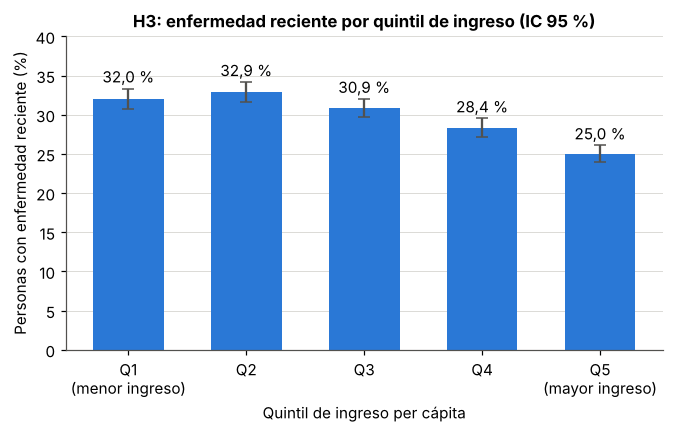

In [6]:
enfermo_q = con_quintil["enfermedad_reciente"].to_numpy()
prev_quintil = []
for q in range(1, 6):
    mascara = (con_quintil["quintil"] == q).to_numpy()
    r = remuestreo.ic_bootstrap(np.mean, enfermo_q[mascara], conglomerados=con_quintil.loc[mascara, "UPM"], n_rep=1000)
    prev_quintil.append({"quintil": q, "prevalencia": r["estimacion"] * 100, "inf": r["inf"] * 100, "sup": r["sup"] * 100})
prev_quintil = pd.DataFrame(prev_quintil).set_index("quintil")

fig, eje = plt.subplots(figsize=(7, 3.7))
eje.bar(prev_quintil.index, prev_quintil["prevalencia"], width=0.6, color=datos.AZUL)
eje.errorbar(prev_quintil.index, prev_quintil["prevalencia"],
             yerr=[prev_quintil["prevalencia"] - prev_quintil["inf"], prev_quintil["sup"] - prev_quintil["prevalencia"]],
             fmt="none", color=datos.GRIS, capsize=4, linewidth=1.5)
for q, fila in prev_quintil.iterrows():
    eje.annotate(f"{fila['prevalencia']:.1f} %".replace(".", ","), (q, fila["sup"]), xytext=(0, 4), textcoords="offset points", ha="center")
eje.set_xticks(range(1, 6), ["Q1\n(menor ingreso)", "Q2", "Q3", "Q4", "Q5\n(mayor ingreso)"])
eje.set_ylim(0, 40)
eje.grid(axis="x", visible=False)
eje.set_xlabel("Quintil de ingreso per cápita")
eje.set_ylabel("Personas con enfermedad reciente (%)")
eje.set_title("H3: enfermedad reciente por quintil de ingreso (IC 95 %)")
datos.guardar_figura(fig, "f2_07_h3_quintiles.png")
plt.show()

**Interpretación del gráfico.** Las barras muestran la proporción muestral con su IC 95 % por bootstrap de UPM. Los tres primeros quintiles tienen proporciones cercanas, entre 30,9 % y 32,9 %. A partir del cuarto quintil la proporción baja (28,4 %), y el quinto, de mayor ingreso, queda claramente separado con 25,0 %. No es un descenso parejo: las diferencias son chicas en los ingresos bajos y medios y grandes en los altos.

**Resultado de H3.**

- **Análisis clásico:** χ² = 211,9 con 4 grados de libertad; p < 0,001.
- **Análisis robusto a conglomerados:** χ² de Wald = 110,9 con 4 grados de libertad; p < 0,001. El estadístico se reduce casi a la mitad al reconocer que el quintil es una característica del hogar, pero la conclusión se mantiene con holgura.
- **Tamaño del efecto:** V de Cramér = 0,061 (IC 95 % por bootstrap: 0,051 a 0,073), trivial según la convención. En unidades originales, la diferencia entre el quintil 2 y el quintil 5 es de 7,9 puntos porcentuales.
- **Post hoc:** de las diez comparaciones, ocho son significativas después del ajuste de Benjamini-Hochberg: todas las que involucran a los quintiles 4 o 5, y además la del quintil 2 frente al 3 (2,1 p.p.; p ajustado = 0,020). El quintil 1 no difiere del 2 ni del 3. Los residuos coinciden: el quintil 5 tiene muchos menos enfermos que los esperados (residuo −12,3) y los quintiles 1 y 2 tienen más (5,7 y 7,6).

**En lenguaje llano.** Las personas de hogares con mayores ingresos reportan menos enfermedad. En el quinto de la población con más ingreso enfermó 1 de cada 4 personas; en los tres quintos de menor ingreso, casi 1 de cada 3.

**Significancia frente a relevancia.** La V de Cramér es baja porque resume toda la tabla, incluidos tres quintiles con proporciones cercanas. La diferencia concentrada entre los extremos (cerca de 8 p.p.) es la mayor encontrada entre grupos socioeconómicos en este trabajo y sí tiene relevancia práctica.

**Posible variable de confusión.** El ingreso se relaciona con el área (los hogares rurales están sobrerrepresentados en los quintiles bajos), con la edad de los integrantes y con la tenencia de seguro. No puede afirmarse que el ingreso por sí mismo proteja de la enfermedad. También podría haber causalidad inversa (una persona enferma puede trabajar menos y reducir el ingreso de su hogar). H6 considera estos factores en conjunto.

## 2. H6: asociación entre seguro y enfermedad controlando otras variables

La Fase 1 concluyó que las personas con seguro tienen más edad, más educación y más ingreso que las personas sin seguro, y que por eso había que evaluar si la relación entre seguro y enfermedad se mantiene al considerar esas características. H1 comparó los grupos en bruto; H6 hace la comparación entre personas de la misma edad, sexo, área y quintil.

- **H0:** β_seguro = 0. Entre personas de igual grupo de edad, sexo, área y quintil de ingreso, tener seguro no se asocia con la enfermedad reciente (razón de odds ajustada = 1).
- **H1:** β_seguro ≠ 0 (bilateral, α = 0,05).

**Selección de la prueba.** Se evalúa la asociación de una variable con la respuesta controlando otras, lo que corresponde a una regresión múltiple con prueba sobre el coeficiente. La variable de respuesta es binaria, de modo que una regresión lineal incumpliría por construcción la normalidad y la homogeneidad de varianza de los residuos. Se usa su equivalente para respuestas binarias, la **regresión logística**, con prueba de Wald sobre el coeficiente del seguro y errores estándar robustos a conglomerados (la variante robusta de la regresión).

**Variables de control y su justificación:**

| Variable | Forma | Por qué se incluye |
|---|---|---|
| Edad | Seis tramos, referencia 15 a 29 años | Relación en forma de U con la enfermedad (Parte 2); los asegurados son mayores |
| Sexo | Referencia: hombre | Diferencia descriptiva de enfermedad en la Fase 1 |
| Área | Referencia: urbana | Asociada con la enfermedad (H5) y con el acceso a seguro |
| Quintil de ingreso | Cinco categorías, referencia Q1 | Asociado con la enfermedad (H3); los asegurados tienen el doble de ingreso mediano |

Los años de estudio no se incluyen: faltan en el 83 % de los menores de 5 años y en el resto de los niños dependen de la edad, por lo que su inclusión eliminaría justo al grupo con más enfermedad.

### 2.1 Verificación de supuestos

In [7]:
formula_completa = ("enfermedad_reciente ~ tiene_seguro + C(grupo_edad, Treatment('15-29')) "
                    "+ C(sexo, Treatment('Hombre')) + C(area, Treatment('Urbana')) + C(quintil, Treatment(1))")

modelo_clasico = smf.logit(formula_completa, data=con_quintil).fit(disp=False)
modelo_robusto = smf.logit(formula_completa, data=con_quintil).fit(
    disp=False, cov_type="cluster", cov_kwds={"groups": con_quintil["UPM"]})

# Multicolinealidad: factor de inflación de la varianza de cada columna del modelo
matriz = pd.DataFrame(modelo_clasico.model.exog, columns=modelo_clasico.model.exog_names)
vif = pd.Series({col: variance_inflation_factor(matriz.to_numpy(), i) for i, col in enumerate(matriz.columns) if col != "Intercept"})

eventos = int(con_quintil["enfermedad_reciente"].sum())
parametros = int(modelo_clasico.df_model)
celda_minima = con_quintil.groupby(["tiene_seguro", "grupo_edad"], observed=True)["enfermedad_reciente"].agg(["size", "sum"])

print(f"Convergencia del ajuste: {modelo_clasico.mle_retvals['converged']}")
print(f"VIF máximo: {vif.max():.2f} ({vif.idxmax()}) | VIF del seguro: {vif['tiene_seguro']:.2f}")
print(f"Eventos (personas enfermas): {eventos:,} | parámetros: {parametros} | eventos por parámetro: {eventos / parametros:,.0f}")
print(f"Celda más chica de seguro × grupo de edad: {int(celda_minima['size'].min())} personas, {int(celda_minima['sum'].min())} enfermas")

Convergencia del ajuste: True
VIF máximo: 1.80 (C(quintil, Treatment(1))[T.5]) | VIF del seguro: 1.25
Eventos (personas enfermas): 17,141 | parámetros: 12 | eventos por parámetro: 1,428
Celda más chica de seguro × grupo de edad: 982 personas, 370 enfermas


| Supuesto de la regresión logística | Verificación | Resultado |
|---|---|---|
| Variable de respuesta binaria | `enfermedad_reciente` vale 0 o 1 | Se cumple |
| Ausencia de multicolinealidad | VIF máximo = 1,80; VIF del seguro = 1,25 (se considera problemático por encima de 5) | Se cumple |
| Linealidad entre predictores numéricos y el logit | Todos los predictores son categóricos; la edad se usa en tramos justamente porque su relación con la enfermedad no es lineal | No aplica (se evita por diseño) |
| Tamaño de muestra suficiente, sin separación | 1.428 eventos por parámetro; el ajuste converge; la celda más chica de seguro por grupo de edad tiene 982 personas | Se cumple |
| Independencia de las observaciones | ICC por hogar 0,31 | **No se cumple** |

**Decisión:** se ajusta la regresión logística y la prueba sobre el coeficiente del seguro usa **errores estándar robustos agrupados por UPM**. El valor p clásico se informa como referencia.

### 2.2 Ejecución de la prueba

In [8]:
def fila_seguro(ajuste):
    b, ee = ajuste.params["tiene_seguro"], ajuste.bse["tiene_seguro"]
    return {"OR": np.exp(b), "IC 95 % inf.": np.exp(b - 1.959964 * ee), "IC 95 % sup.": np.exp(b + 1.959964 * ee),
            "z": b / ee, "p": ajuste.pvalues["tiene_seguro"]}


coef_clasico, coef_robusto = fila_seguro(modelo_clasico), fila_seguro(modelo_robusto)

# Prueba global: todos los coeficientes (salvo el intercepto) valen cero
k = len(modelo_robusto.params)
wald_global = modelo_robusto.wald_test(np.eye(k)[1:], use_f=False, scalar=True)

# Efecto marginal promedio: diferencia en probabilidad de enfermedad atribuible al seguro, en puntos porcentuales
margenes = modelo_robusto.get_margeff().summary_frame().loc["tiene_seguro"]

pd.Series({
    "n": int(modelo_robusto.nobs),
    "OR ajustado del seguro": coef_robusto["OR"],
    "IC 95 % robusto, inferior": coef_robusto["IC 95 % inf."],
    "IC 95 % robusto, superior": coef_robusto["IC 95 % sup."],
    "z de Wald clásico": coef_clasico["z"],
    "Valor p clásico": coef_clasico["p"],
    "z de Wald robusto": coef_robusto["z"],
    "Valor p robusto": coef_robusto["p"],
    "Efecto marginal promedio (p.p.)": margenes["dy/dx"] * 100,
    "  IC 95 % inferior (p.p.)": margenes["Conf. Int. Low"] * 100,
    "  IC 95 % superior (p.p.)": margenes["Cont. Int. Hi."] * 100,
    "Prueba global: razón de verosimilitud χ² (gl = 12)": modelo_clasico.llr,
    "Prueba global: valor p": max(modelo_clasico.llr_pvalue, 1e-300),   # menor a 1e-300: se muestra ese tope
    "Prueba global robusta: Wald χ² (gl = 12)": wald_global.statistic,
    "Prueba global robusta: valor p": max(float(wald_global.pvalue), 1e-300),
    "Pseudo R² de McFadden": modelo_clasico.prsquared,
}, name="H6").to_frame()

,H6
n,"56,979.0000"
OR ajustado del seguro,1.0065
"IC 95 % robusto, inferior",0.9508
"IC 95 % robusto, superior",1.0655
z de Wald clásico,0.2740
Valor p clásico,0.7841
z de Wald robusto,0.2239
Valor p robusto,0.8229
Efecto marginal promedio (p.p.),0.1325
IC 95 % inferior (p.p.),-1.0279


In [9]:
magnitud_h6 = efectos.magnitud(coef_robusto["OR"], "or")
registro.agregar(
    id="H6",
    hipotesis="El seguro se asocia con la enfermedad al controlar edad, sexo, área y quintil",
    variables="enfermedad_reciente ~ tiene_seguro + grupo_edad + sexo + area + quintil",
    familia="Efecto de una variable controlando otras",
    prueba="Regresión logística (Wald sobre el coeficiente)",
    supuestos="VIF < 2, tamaño y convergencia: cumplen. Independencia: no cumple, se usan EE robustos por UPM",
    n=int(modelo_robusto.nobs),
    estadistico="z", valor_estadistico=coef_clasico["z"], gl=np.nan,
    p_clasico=coef_clasico["p"], p_robusto=coef_robusto["p"],
    efecto="OR ajustado", valor_efecto=coef_robusto["OR"], magnitud=magnitud_h6,
    ic_parametro="OR ajustado del seguro",
    ic_inf=coef_robusto["IC 95 % inf."], ic_sup=coef_robusto["IC 95 % sup."], ic_metodo="Wald robusto por UPM",
)

### 2.3 Qué variable explica la diferencia bruta: análisis de confusión

Para entender por qué el efecto del seguro cambia, se agregan los controles de a uno. Estos modelos intermedios son descriptivos: muestran cómo se mueve la razón de odds del seguro, y no se usan para tomar decisiones adicionales.

In [10]:
edad_t = "C(grupo_edad, Treatment('15-29'))"
sexo_t, area_t, quintil_t = "C(sexo, Treatment('Hombre'))", "C(area, Treatment('Urbana'))", "C(quintil, Treatment(1))"
secuencia = {
    "M0. Solo seguro (bruto)": "enfermedad_reciente ~ tiene_seguro",
    "M1. + edad": f"enfermedad_reciente ~ tiene_seguro + {edad_t}",
    "M2. + edad, sexo y área": f"enfermedad_reciente ~ tiene_seguro + {edad_t} + {sexo_t} + {area_t}",
    "M3. + edad, sexo, área y quintil": formula_completa,
    "M4. M3 + trimestre (sensibilidad)": formula_completa + " + C(trimestre)",
}
filas = {}
for nombre, formula in secuencia.items():
    ajuste = smf.logit(formula, data=con_quintil).fit(disp=False, cov_type="cluster", cov_kwds={"groups": con_quintil["UPM"]})
    filas[nombre] = fila_seguro(ajuste)
confusion = pd.DataFrame(filas).T[["OR", "IC 95 % inf.", "IC 95 % sup."]]
confusion.to_csv(datos.ruta_salida("h6_or_seguro_por_modelo.csv"))
display(confusion.round(3))

# Razones de odds de todas las variables del modelo completo
etiquetas = {
    "tiene_seguro": "Con seguro (ref.: sin seguro)",
    "C(grupo_edad, Treatment('15-29'))[T.0-4]": "Edad 0-4 (ref.: 15-29)",
    "C(grupo_edad, Treatment('15-29'))[T.5-14]": "Edad 5-14",
    "C(grupo_edad, Treatment('15-29'))[T.30-44]": "Edad 30-44",
    "C(grupo_edad, Treatment('15-29'))[T.45-59]": "Edad 45-59",
    "C(grupo_edad, Treatment('15-29'))[T.60+]": "Edad 60+",
    "C(sexo, Treatment('Hombre'))[T.Mujer]": "Mujer (ref.: hombre)",
    "C(area, Treatment('Urbana'))[T.Rural]": "Rural (ref.: urbana)",
    "C(quintil, Treatment(1))[T.2]": "Quintil 2 (ref.: Q1)",
    "C(quintil, Treatment(1))[T.3]": "Quintil 3",
    "C(quintil, Treatment(1))[T.4]": "Quintil 4",
    "C(quintil, Treatment(1))[T.5]": "Quintil 5",
}
ic = modelo_robusto.conf_int()
or_completo = pd.DataFrame({
    "OR": np.exp(modelo_robusto.params), "IC 95 % inf.": np.exp(ic[0]), "IC 95 % sup.": np.exp(ic[1]),
    "p robusto": modelo_robusto.pvalues,
}).loc[list(etiquetas)].rename(index=etiquetas)
or_completo.to_csv(datos.ruta_salida("h6_or_modelo_completo.csv"))
or_completo.round(3)

,OR,IC 95 % inf.,IC 95 % sup.
M0. Solo seguro (bruto),0.9320,0.8830,0.9830
M1. + edad,0.8860,0.8390,0.9360
"M2. + edad, sexo y área",0.9100,0.8610,0.9620
"M3. + edad, sexo, área y quintil",1.0070,0.9510,1.0650
M4. M3 + trimestre (sensibilidad),1.0050,0.9490,1.0630


,OR,IC 95 % inf.,IC 95 % sup.,p robusto
Con seguro (ref.: sin seguro),1.0070,0.9510,1.0650,0.8230
Edad 0-4 (ref.: 15-29),2.1110,1.9490,2.2860,0.0000
Edad 5-14,1.5370,1.4440,1.6370,0.0000
Edad 30-44,1.1860,1.1180,1.2570,0.0000
Edad 45-59,1.6190,1.5230,1.7200,0.0000
Edad 60+,2.6920,2.5240,2.8720,0.0000
Mujer (ref.: hombre),1.2700,1.2280,1.3130,0.0000
Rural (ref.: urbana),1.0870,1.0180,1.1600,0.0130
Quintil 2 (ref.: Q1),1.0490,0.9660,1.1390,0.2550
Quintil 3,0.9700,0.8910,1.0550,0.4760


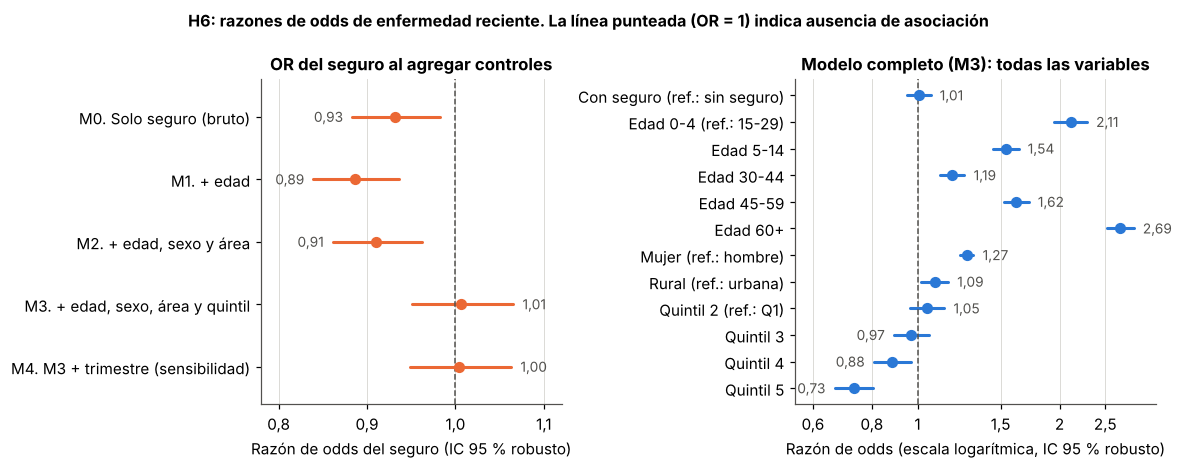

In [11]:
fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(10.8, 4.3), gridspec_kw={"width_ratios": [1, 1.2]})

def bosque(eje, tabla, color):
    pos = np.arange(len(tabla))[::-1]
    for p, (_, fila) in zip(pos, tabla.iterrows()):
        eje.plot([fila["IC 95 % inf."], fila["IC 95 % sup."]], [p, p], color=color, linewidth=2, solid_capstyle="round")
        eje.scatter(fila["OR"], p, color=color, s=40, zorder=3)
        # La etiqueta va del lado opuesto a la línea de referencia para no taparla
        if fila["OR"] >= 1:
            ancla, desplazamiento, alineacion = fila["IC 95 % sup."], (6, 0), "left"
        else:
            ancla, desplazamiento, alineacion = fila["IC 95 % inf."], (-6, 0), "right"
        eje.annotate(f"{fila['OR']:.2f}".replace(".", ","), (ancla, p), xytext=desplazamiento,
                     textcoords="offset points", va="center", ha=alineacion, fontsize=9, color=datos.GRIS)
    eje.axvline(1, color=datos.GRIS, linestyle="--", linewidth=1)
    eje.set_yticks(pos, tabla.index)
    eje.set_ylim(-0.6, len(tabla) - 0.4)
    eje.grid(axis="y", visible=False)

bosque(eje1, confusion, datos.NARANJA)
eje1.set_xlim(0.78, 1.12)
datos.ejes_con_coma(eje1, decimales_x=1)
eje1.set_xlabel("Razón de odds del seguro (IC 95 % robusto)")
eje1.set_title("OR del seguro al agregar controles")

bosque(eje2, or_completo, datos.AZUL)
eje2.set_xscale("log")
eje2.set_xticks([0.6, 0.8, 1, 1.5, 2, 2.5], ["0,6", "0,8", "1", "1,5", "2", "2,5"])
eje2.minorticks_off()
eje2.set_xlim(0.55, 3.2)
eje2.set_xlabel("Razón de odds (escala logarítmica, IC 95 % robusto)")
eje2.set_title("Modelo completo (M3): todas las variables")
fig.suptitle("H6: razones de odds de enfermedad reciente. La línea punteada (OR = 1) indica ausencia de asociación",
             fontweight="bold", fontsize=10.5)
fig.tight_layout()
datos.guardar_figura(fig, "f2_08_h6_razones_de_odds.png")
plt.show()

**Interpretación del gráfico.** A la izquierda se ve el recorrido de la razón de odds (OR) del seguro. En bruto es 0,93 (los asegurados reportan algo menos de enfermedad). Al controlar la edad baja a 0,89: los asegurados son mayores y los mayores enferman más, de modo que a igual edad la diferencia es algo más marcada. Al agregar el quintil de ingreso el OR sube a 1,01 y su intervalo queda centrado en 1. Agregar además el trimestre de entrevista (M4) no lo modifica: OR = 1,005. A la derecha, el modelo completo muestra qué variables sí se asocian con la enfermedad: la edad (los menores de 5 y los mayores de 60 años tienen más del doble de odds que el grupo de 15 a 29), el sexo (mujeres, OR 1,27) y el quintil 5 (OR 0,73).

**Resultado de H6.**

- **Coeficiente del seguro:** OR ajustado = 1,007; IC 95 % robusto de 0,951 a 1,065; z robusto = 0,22; p = 0,82 (clásico: z = 0,27; p = 0,78).
- **Efecto marginal promedio:** +0,13 puntos porcentuales (IC 95 %: −1,03 a 1,29).
- **Prueba global del modelo:** Wald robusto χ² = 1.489 con 12 grados de libertad; p < 0,001 (razón de verosimilitud clásica: χ² = 1.736). El modelo en conjunto explica algo, aunque poco: pseudo R² de McFadden = 0,025.
- **Tamaño del efecto:** trivial.

**En lenguaje llano.** Cuando se comparan personas de la misma edad, sexo, área y nivel de ingreso, quienes tienen seguro y quienes no lo tienen reportan enfermedad prácticamente en la misma proporción. La pequeña diferencia bruta de H1 deja de observarse al tener en cuenta el ingreso: los asegurados pertenecen a hogares de mayores ingresos, y esos hogares reportan menos enfermedad, tengan o no seguro.

**Lo que no se puede afirmar.** No rechazar H0 no demuestra que no exista asociación. Lo que muestran los datos es que el intervalo de confianza es estrecho: es compatible, como mucho, con una diferencia de alrededor de 1 punto porcentual en cualquier sentido. Una asociación grande queda descartada por estos datos; una muy pequeña, no. Tampoco se trata de un efecto causal: es una comparación ajustada en datos observacionales.

**Variables de confusión identificadas.** El quintil de ingreso es la variable que más modifica la asociación entre seguro y enfermedad, y la edad actúa en sentido contrario. El trimestre de entrevista no la modifica. Quedan fuera del modelo otros posibles factores no medidos en la base: enfermedades crónicas previas, tipo de empleo y, sobre todo, el hecho de que la enfermedad es autorreportada y quien tiene seguro puede percibir o recordar sus episodios de manera distinta.

## 3. Comparaciones múltiples y tabla resumen de contrastes

Se reúnen los seis contrastes confirmatorios guardados por las tres partes y se aplica la regla declarada en la Parte 1: la decisión usa el valor p robusto a conglomerados ajustado por **Bonferroni** (se multiplica por 6). El ajuste es necesario porque, con seis pruebas al 5 %, la probabilidad de al menos un falso positivo sería de 26,5 % si todas las hipótesis nulas fueran ciertas.

**Cantidad total de pruebas realizadas en la fase:** 6 contrastes confirmatorios (corregidos por Bonferroni), 10 comparaciones post hoc entre quintiles (corregidas por Benjamini-Hochberg) y 6 pruebas de supuestos (5 de Shapiro-Wilk y 1 de Levene, que no contrastan hipótesis de investigación). Además se informan de forma descriptiva, sin usarlas para decidir sobre ninguna hipótesis, la prueba global del modelo de H6, los intervalos de sus demás coeficientes, los modelos M0 a M4 y la diferencia de H5 controlando el trimestre. No se descartó ningún resultado.

In [12]:
registro.guardar()
contrastes = resumen.cargar_contrastes()
tabla_completa = resumen.aplicar_correcciones(contrastes)
tabla_legible = resumen.tabla_para_informe(tabla_completa)
rutas = resumen.exportar(tabla_completa, tabla_legible)
print("Tabla resumen exportada en:", ", ".join(str(r.relative_to(RAIZ)) for r in rutas.values()))

tabla_legible.style.hide(axis="index").set_properties(**{"text-align": "left", "vertical-align": "top", "font-size": "11px"})

Tabla resumen exportada en: output/fase2/tabla_resumen_contrastes.csv, output/fase2/tabla_resumen_contrastes_legible.csv, output/fase2/tabla_resumen_contrastes.md


Hipótesis,Prueba,Supuestos verificados,Estadístico,p clásico,p robusto,p robusto (Bonferroni),IC 95 %,Tamaño del efecto,Decisión
H1. La proporción de enfermedad reciente difiere entre personas con y sin seguro,z de dos proporciones,"Tamaño: cumple. Independencia: no cumple (ICC hogar 0,31), se usa EE robusto por UPM","z = −3,33","< 0,001","0,010","0,063","Diferencia con − sin, en p.p.: [−2,536; −0,320] (bootstrap por UPM)","h de Cohen = −0,032 (trivial)",No se rechaza H0
H2. La edad difiere entre personas con y sin enfermedad reciente,U de Mann-Whitney,"Normalidad: no cumple (Shapiro-Wilk, Q-Q). Varianzas: no cumple (Levene). Se descarta t de Student","z = 12,05","< 0,001","< 0,001","< 0,001","P(edad enfermo > edad sano): [0,526; 0,538] (bootstrap por UPM)","r biserial por rangos = 0,063 (trivial)",Se rechaza H0
H3. La enfermedad reciente no se distribuye igual entre quintiles de ingreso,Chi-cuadrado de independencia,"Esperadas ≥ 5: cumple. Independencia: no cumple (quintil común al hogar), se usa Wald robusto por UPM","χ² = 211,91 (gl = 4)","< 0,001","< 0,001","< 0,001","V de Cramér: [0,051; 0,073] (bootstrap por UPM)","V de Cramér = 0,061 (trivial)",Se rechaza H0
H4. Asociación positiva entre años de estudio e ingreso per cápita (25 años o más),rho de Spearman (unilateral),"Normalidad, linealidad y extremos: no cumplen, se descarta Pearson. Monotonía: cumple de forma aproximada","t = 97,51 (gl = 33485)","< 0,001","< 0,001","< 0,001","rho de Spearman: [0,457; 0,483] (bootstrap por UPM)","rho de Spearman = 0,470 (mediano)",Se rechaza H0
H5. La proporción de enfermedad reciente difiere entre área rural y urbana,z de dos proporciones,"Tamaño: cumple. Independencia: no cumple (área constante por UPM), se usa EE robusto por UPM","z = 8,00","< 0,001","< 0,001","< 0,001","Diferencia rural − urbana, en p.p.: [1,841; 4,420] (bootstrap por UPM)","h de Cohen = 0,068 (trivial)",Se rechaza H0
"H6. El seguro se asocia con la enfermedad al controlar edad, sexo, área y quintil",Regresión logística (Wald sobre el coeficiente),"VIF < 2, tamaño y convergencia: cumplen. Independencia: no cumple, se usan EE robustos por UPM","z = 0,27","0,784","0,823","1,000","OR ajustado del seguro: [0,951; 1,065] (Wald robusto por UPM)","OR ajustado = 1,007 (trivial)",No se rechaza H0


In [13]:
# Valores numéricos exactos de la corrección (sin redondeo de presentación)
tabla_completa[["id", "n", "valor_estadistico", "gl", "p_clasico", "p_robusto", "p_robusto_bonferroni", "p_robusto_holm", "p_robusto_bh",
                "valor_efecto", "magnitud", "decision", "decision_clasica"]].style.hide(axis="index").format({
    "valor_estadistico": "{:.3f}", "gl": "{:.0f}", "p_clasico": "{:.2e}", "p_robusto": "{:.2e}",
    "p_robusto_bonferroni": "{:.2e}", "p_robusto_holm": "{:.2e}", "p_robusto_bh": "{:.2e}", "valor_efecto": "{:.4f}",
}, na_rep="")

id,n,valor_estadistico,gl,p_clasico,p_robusto,p_robusto_bonferroni,p_robusto_holm,p_robusto_bh,valor_efecto,magnitud,decision,decision_clasica
H1,57109,-3.334,,8.56e-04,1.05e-02,6.28e-02,2.09e-02,1.26e-02,-0.0317,trivial,No se rechaza H0,Se rechaza H0
H2,57109,12.051,,1.91e-33,3.10e-22,1.86e-21,1.24e-21,6.20e-22,0.0635,trivial,Se rechaza H0,Se rechaza H0
H3,56979,211.914,4,1.03e-44,4.59e-23,2.75e-22,2.30e-22,1.38e-22,0.0610,trivial,Se rechaza H0,Se rechaza H0
H4,33487,97.508,33485,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.4703,mediano,Se rechaza H0,Se rechaza H0
H5,57109,8.004,,1.21e-15,2.75e-06,1.65e-05,8.26e-06,4.13e-06,0.0677,trivial,Se rechaza H0,Se rechaza H0
H6,56979,0.274,,7.84e-01,8.23e-01,1.00e+00,8.23e-01,8.23e-01,1.0065,trivial,No se rechaza H0,No se rechaza H0


**Lectura de la tabla.**

- **H2, H3, H4 y H5 se rechazan** con cualquier criterio: clásico o robusto, con Bonferroni o con Benjamini-Hochberg.
- **H6 no se rechaza** con ningún criterio (p = 0,82).
- **H1 es el único contraste cuya decisión depende del método.** Con el análisis clásico se rechazaría (p ajustado = 0,005). Con el análisis robusto y Bonferroni, que es el criterio declarado de antemano, **no se rechaza** (p ajustado = 0,063). Con criterios menos conservadores sobre el mismo valor p robusto sí se rechazaría: Holm da 0,021 y Benjamini-Hochberg, 0,013. Una conclusión que cambia según el criterio es una evidencia frágil, y así se informa.

## 4. Conclusión de la Fase 2

### 4.1 Qué hipótesis se sostuvieron

| Hipótesis | Resultado | Tamaño del efecto |
|---|---|---|
| H1. Enfermedad difiere según seguro | **No se sostiene** con el criterio declarado; evidencia frágil | Trivial: −1,45 p.p.; h = −0,03 |
| H2. Edad difiere según enfermedad | **Se sostiene** | Trivial como desplazamiento (r = 0,06), pero la relación tiene forma de U y es fuerte por tramos |
| H3. Enfermedad difiere según quintil | **Se sostiene** | V = 0,06; hasta 7,9 p.p. entre quintiles |
| H4. Educación e ingreso se asocian positivamente | **Se sostiene** | Mediano: ρ = 0,47 |
| H5. Enfermedad difiere según área | **Se sostiene** | Trivial según la convención (h = 0,07); +3,1 p.p. en el área rural |
| H6. El seguro se asocia con la enfermedad al controlar otras variables | **No se sostiene** (no se rechaza H0) | Trivial: OR = 1,01 |

### 4.2 Qué implica para la pregunta de investigación

La pregunta era si la proporción de personas que reportaron enfermedad en los últimos 90 días difiere entre quienes tienen y quienes no tienen seguro médico. La respuesta que permite la evidencia es:

1. **En bruto, la diferencia es de 1,45 puntos porcentuales** (28,99 % con seguro, 30,44 % sin seguro). Es demasiado pequeña para tener relevancia práctica y, una vez considerada la dependencia entre integrantes de un mismo hogar, no alcanza significancia con el criterio de corrección declarado (Bonferroni), aunque sí con criterios menos conservadores.
2. **Al comparar personas de igual edad, sexo, área e ingreso, la diferencia deja de observarse** (OR = 1,01; IC 95 %: 0,95 a 1,07). La diferencia bruta coincide con la distinta composición por ingreso de los hogares asegurados.
3. **Lo que sí se asocia con la enfermedad reciente** es la edad (en forma de U), el sexo, el quintil de ingreso y, en menor medida, el área de residencia. De forma descriptiva se observa además un patrón por trimestre de entrevista (Parte 1, sección 3.1).

Ninguna de estas asociaciones puede leerse como causal: la EPHC es una encuesta transversal y observacional.

### 4.3 Limitaciones de la inferencia

- **Dependencia entre observaciones.** Es la limitación principal. La enfermedad se concentra por hogar (ICC = 0,31) y el diseño es por conglomerados. Se abordó con errores robustos y bootstrap por UPM, pero no se dispone de los estratos del diseño muestral, por lo que los errores estándar siguen siendo aproximados.
- **Representatividad.** Las pruebas se hicieron sobre la muestra sin ponderar. La muestra sobrerrepresenta áreas rurales y departamentos chicos, de modo que las proporciones muestrales no coinciden exactamente con las poblacionales. En H1 la estimación ponderada (−1,31 p.p.) lleva a la misma conclusión.
- **Tamaño muestral.** Con 57.109 personas, diferencias mínimas resultan significativas en las pruebas clásicas. Por eso todas las conclusiones se apoyan en el tamaño del efecto y no solo en el valor p.
- **Dependencia temporal.** Al enlazar los archivos trimestrales se recuperó el trimestre de entrevista y se observó un patrón estacional: la proporción de enfermedad es 27,4 % y 28,5 % en el primer y el cuarto trimestre, y 32,1 % y 32,6 % en el segundo y el tercero (Parte 1, sección 3.1). La dependencia que el trimestre introduce dentro de cada UPM queda cubierta por los errores por UPM; la que podría introducir entre UPM del mismo trimestre se comprobó agregando el trimestre como control en H5 y en el modelo M4 de H6, sin cambios (OR = 1,005). Quedan dos límites: solo se dispone del trimestre, no de la fecha exacta, y con un único año no puede separarse la estación de otros hechos ocurridos en 2024.
- **Medición.** La enfermedad es autorreportada con un período de recuerdo de 90 días, y en niños la reporta un adulto. El seguro puede influir en cómo se percibe o recuerda una enfermedad.
- **Datos faltantes.** Se excluyeron 130 personas sin ingreso (0,23 %) en H3 y H6, y en H4 se usaron solo adultos con ambos datos. El impacto esperado es mínimo.

### 4.4 Variables que se llevan al modelo predictivo de la Fase 3

| Variable | Decisión | Evidencia de esta fase |
|---|---|---|
| Edad | **Se incluye**, en tramos o con un modelo que capte relaciones no lineales | Relación en U; es el predictor más fuerte en H6 |
| Sexo | **Se incluye** | OR = 1,27 en el modelo de H6 |
| Quintil o ingreso per cápita | **Se incluye** | H3; es la variable que más modifica la asociación del seguro en H6 |
| Área | **Se incluye** | H5; conserva asociación propia en H6 (OR = 1,09) |
| Trimestre de entrevista | Depende de la partición (ver abajo) | Patrón estacional de 3,6 a 5,2 p.p. (Parte 1, sección 3.1) |
| Tiene seguro | **Se incluye**, por ser la variable de la pregunta de investigación | Sin asociación propia en H6: se espera una importancia baja, y la Fase 3 debe confirmarlo |
| Años de estudio | Se evalúa con cuidado | Correlacionado con el ingreso (ρ = 0,47, H4) y sin dato en menores de 5 años |
| Departamento, estado civil | Se evalúan en la Fase 3 | No fueron contrastados en esta fase |

Tres advertencias para el diseño de la Fase 3 que surgen de esta evidencia:

1. **La partición no debe separar personas del mismo hogar ni de la misma UPM.** Como los integrantes de un hogar tienden a enfermarse juntos, repartirlos al azar entre entrenamiento y prueba filtraría información y haría parecer al modelo mejor de lo que es.
2. **La base tiene componente temporal y hay dos diseños de partición válidos.** (a) Cronológico: entrenar con los tres primeros trimestres y probar con el cuarto. Cumple con el punto anterior, porque cada UPM pertenece a un solo trimestre, pero impide usar el trimestre como predictor (el cuarto nunca aparece en el entrenamiento) y el conjunto de prueba tiene otra composición: 28,5 % de enfermedad frente a 30,7 % en el entrenamiento, y 46,1 % de área rural frente a 40,9 %. (b) Agrupado por UPM, sin orden temporal: permite usar el trimestre como predictor. La consigna pide partición cronológica cuando hay componente temporal, por lo que se propone (a) como diseño principal y (b) como comprobación; la decisión se toma y se justifica en la Fase 3.
3. **Cabe esperar un desempeño predictivo modesto.** El modelo de H6 tiene un pseudo R² de 0,025: las variables disponibles explican una parte pequeña de quién enferma.